In [31]:
!pip install torchviz

In [168]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import torch.optim as optim
import torchviz

# 1

In [198]:
def trueFunc(x):
    a=1.5
    b=4
    return a*x+b

def noise_data(x, y):
    mean=0
    std=0.2
    noise=np.random.normal(mean, std, y.shape)
    return (y + noise)

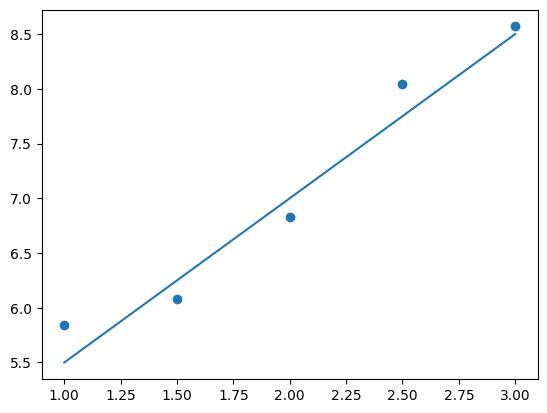

In [199]:
N=5
x=np.linspace(1, 3, N)
y_true=trueFunc(x)
y_noise=noise_data(x, y_true)

plt.plot(x, y_true)
plt.scatter(x, y_noise)
plt.show()

2

In [200]:
x_tensor=torch.from_numpy(x)
x_tensor.requires_grad=True
y_tensor=torch.from_numpy(y_noise)
y_tensor.requires_grad=True

w = torch.randn(1, 1, requires_grad=True)
b = torch.randn(1, 1, requires_grad=True)
z = x_tensor*w+b

loss = torch.mean((z-y_tensor)**2)

print(loss)

tensor(13.4760, dtype=torch.float64, grad_fn=<MeanBackward0>)

In [201]:
optimizer=optim.Adam([w, b], lr=1e-2)

In [202]:
loss_hist=[]
w_pred=[]
b_pred=[]
Nepoch=5000
for i in range(Nepoch):

    # обнулить производные, чтобы они не суммировались на каждом шаге
    optimizer.zero_grad()

    # сделать предсказание
    z = x_tensor*w+b

    # посчитать лосс
    loss = torch.mean((z-y_tensor)**2)

    # посчитать производные (d Loss/d w и d Loss/d b) и просуммировать
    loss.backward()

    # обновление весовых коэффициентов
    optimizer.step()

    #логгирование
    loss_hist.append(loss.item())
    w_pred.append(w.item())
    b_pred.append(b.item())

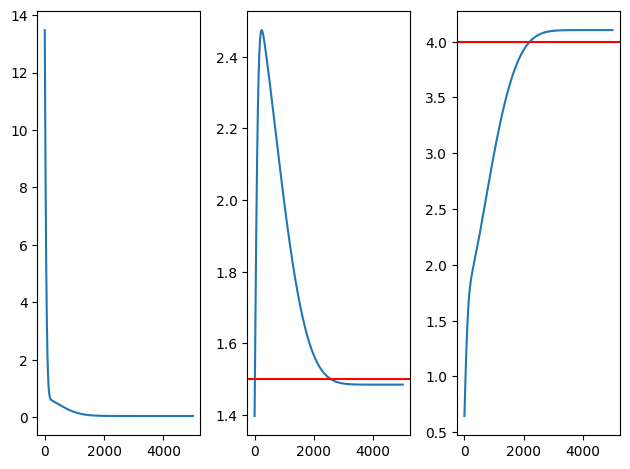

In [203]:
f, ax = plt.subplots(1, 3)

ax[0].plot(loss_hist)
ax[1].plot(w_pred)
ax[1].axhline(y=1.5, c='r')
ax[2].plot(b_pred)
ax[2].axhline(y=4, c='r')

plt.tight_layout()
plt.show()

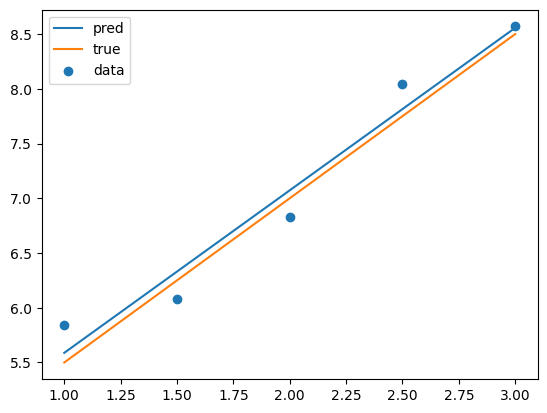

In [204]:
z = x_tensor*w+b

x_pred=x_tensor.detach().cpu().numpy()
z_pred=z.detach().cpu().numpy()[0]

plt.plot(x_pred, z_pred, label='pred')

plt.plot(x, y_true, label='true')
plt.scatter(x, y_noise, label='data')
plt.legend()
plt.show()

 # PyTorch execution graphs

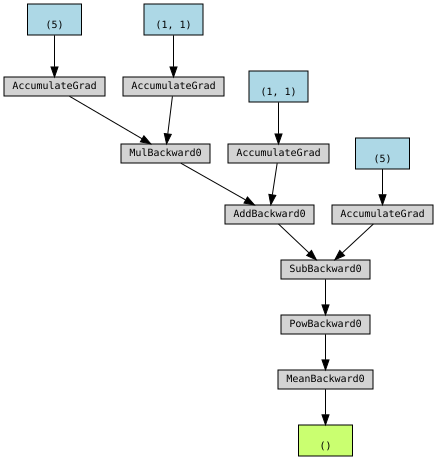

In [175]:
torchviz.make_dot(loss)

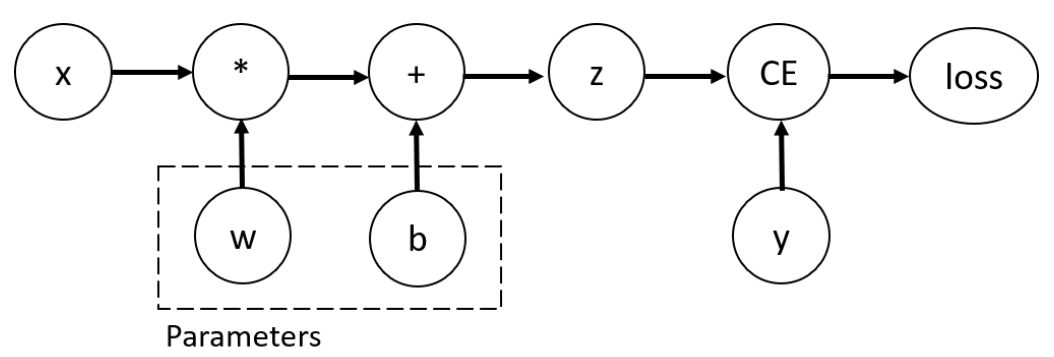

In [190]:
x_tensor.grad

tensor([1.3486, 1.7980, 1.9547, 2.2280, 2.5332], dtype=torch.float64)

In [192]:
# сделать предсказание
z = x_tensor*w+b

# посчитать лосс
loss = torch.mean((z-y_tensor)**2)
#loss.backward()

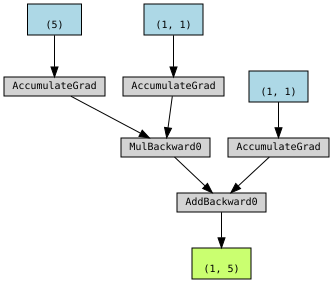

In [185]:
torchviz.make_dot(z)